# **Application of machine learning on prediction of thermal condctivity in SiOC glass ceramics**

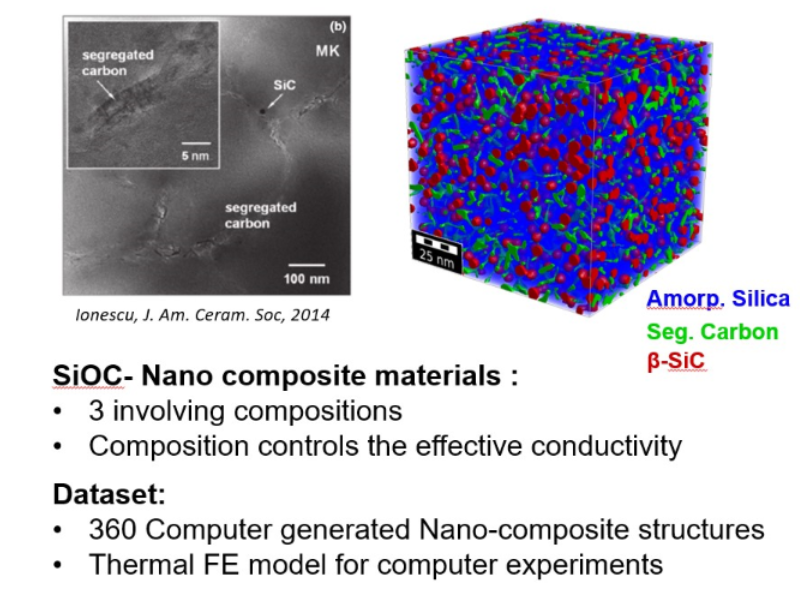

The considered material system is the SiOC glass ceramics, which has the following advanced material properties:
- High chemical durability
- Excellent behavior in oxidative and corrosive environments
- High stability at high temperatures
In the following, we would like to apply machine learning approaches presented in the lectures and exercises to practice and work with featureand image data from this material class. The features are both numericdescriptors, as well as image dataset from simulative basis. The target property is the effective thermal conductivity also from simulative basis.
The dataset for this study consists of 360 three-dimensional image datasets given in .npy files (X, Y,Z each of Dimension 100), which are different in their compositions. The detailed tasks descriptions are given below:

##  Dataset inspection before applying machine learning.
Investigating the data structure of npy files

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
os. getcwd()

In [ ]:
# # load an .npy file (a structure) in the "Data" folder
data_dir = '/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/Data/'
str_list=os.listdir(data_dir) #returns a list containing the names of the entries in the directory

In [ ]:
np.size(str_list)

In [ ]:
len(str_list)                 #dataset for this study consists of 360

In [ ]:
str_list[3]

In [ ]:
data= np.load(data_dir +str_list[1])
print('type of data',type(data))
print('data dimension',data.ndim)    #File contains three dimensional array
print('shape of data',data.shape )   # Axis are 100 units in each of the three dimensions

## Microstruture Visualization
Investigating the 2D cross sections of data structure (.npy files)

![image.png](attachment:image.png)

In [ ]:
zSlicePosition = 10      # position of a microstructure slice along the z-axis for visualisation
data = np.load(data_dir+str_list[100])
dataSlice=data[:,:,zSlicePosition]    # slice at the the x3 dimension and retain x1,x2 untouched

plt.figure(figsize = (4,3))
plt.imshow(dataSlice,interpolation='nearest')
plt.show()

In [ ]:
data

## Calculating volume fractions of different phases

#### Calculation and association of volume fractions
Associating the thermal conductivity to the provided files and numbering them instead of 6-digit alphanumerical denomination

In [ ]:
print(dataSlice)
print(np.unique(dataSlice))

The individual .npy files are made up of  3 dimensional arrays (100x100x100).
Each point represent a spacial coordinate inside a synthetic materialstructure. The values are discrete (0,1,2), each representing a consituent compound.
- 0: Silica (SiO2)
- 1: ß-SiC
- 2: Segregated Carbon

### Calculating Volume Fractions (2D)

In [ ]:
#Calculation of phase VolFrac in 2D slices
plt.rcParams["figure.figsize"] = [12, 8]      # width and height of the sketch
plt.rcParams["figure.autolayout"] = True


for i in range(len(str_list[:4])):
    n0,n1,n2 = 0,0,0                # reset iterative variable
    data = np.load(data_dir+str_list[i])
    dataSlice=data[:,:,zSlicePosition]    # slice at the the x3 dimension and retain x1,x2 untouched


    plt.subplot(4,2,i+1)
    plt.title("Volume fractions of selected compositions")
    plt.imshow(dataSlice)               # Save the plotted images in memory
    plt.axis('off')
    for pixel in np.nditer(dataSlice):   # nditer(): multi-D iterator to iterate over arrays
        if pixel == 1:
            n1 += 1
        elif pixel == 2:
            n2 += 1
        elif pixel == 0:
            n0 += 1
    TotalPixels = dataSlice.size
    plt.title(str_list[i]+" @z="+str(zSlicePosition),fontsize=14)
    plt.title(str(n0*100/TotalPixels)+ "% SiO2\n" +str(n1*100/TotalPixels)+ "% ß-SiC\n" + str(n2*100/TotalPixels)+ "% Seg-C",fontsize=14)

    cbar = plt.colorbar(ticks=[0, 1, 2],shrink=0.4)  # Set the ticks you want

    cbar.set_ticklabels(['SiO2', 'ß-SiC', 'seg_C'])  # Set corresponding tick labels


plt.show()                    # show sketch and plotted images


First calculating all volume fractions which will take some time. Then storing the answers in a numpy array with the name of the files and associate those witht he csv file

In [ ]:
str_list

### Calculating Volume Fractions (3D)

In [ ]:
#Last iteration took 17 min
VolFrac = []       # Volume Fractions as a list (Filename,0,1,2)
Fin = len(str_list)
i=0
for File in str_list:
    #print(File)
    i += 1
    n0,n1,n2 = 0,0,0
    file_path = os.path.join(data_dir, File)
    #print(file_path)
    data = np.load(file_path)
    n1 = np.sum(data == 1)     #this is a much faster way than what was used for the 2D
    n2 = np.sum(data == 2)
    n0 = np.sum(data == 0)
    TotalVoxels = data.size
    VolFrac.append([File,n0/TotalVoxels,n1/TotalVoxels,n2/TotalVoxels])
    print("({i}/{Fin}) {File} (".format(i=i,Fin=Fin,File=File) + str(n0*100/TotalVoxels)+ "%/" +str(n1*100/TotalVoxels)+ "%/" + str(n2*100/TotalVoxels)+ "%)")


In [ ]:
print(VolFrac[0])

In [ ]:
# making a pandas dataframe from the VolFrac list
pd_VolFrac =pd.DataFrame(VolFrac,columns=["File Names","SiO2","ß-SiC","seg-Carbon"])
pd_VolFrac.head()

In [ ]:
#pd_VolFrac[pd_VolFrac['File Names']=='M6LJOC.npy']

#### Merging Thermal Conductivity and Volume Fractions

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/npy_filename_with_thermal_conductivity_group1.csv",usecols = [1,2])   # open the thermal conductivity sheet
df.head(2)

In [ ]:
 # combining the two dataframes including VolFrac and thermalCond. data
Merged = pd.merge(df,pd_VolFrac)
Merged.head(2)
Merged.rename(columns = {'Effective Thermal Cond':'Therm Cond.'}, inplace = True)

In [ ]:
Merged.head(2)

In [ ]:
Merged.to_csv("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/VolumeFraction.csv")       # Save for later

### Primary data exploration

#### Reload stored VolumeFraction.csv

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/VolumeFraction.csv",usecols=[2,3,4,5])
df.head(2)

#### Pairplot

Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical

In [ ]:
import seaborn as sns
sns.pairplot(df)

The pairplot visually represents the correlations between the effective thermal conductivity and the constituents. The plots are in matrix format where the row name represents x axis and column name represents the y axis. The main-diagonal subplots are the univariate histograms (distributions) for each attribute. Qualitative analysis is possible via the scatter plots and histograms.

- The first constituent (SiO2, amorphous silica) displays a generally negative effect on the thermal conductivity. High volume fractions of SiO2 result in an effective thermal conductivty below 2.0.
- The second constituent (ß-SiC) has a positive effect on the thermal conductivity. Structures with high volume fractions of ß-SiC inherit the highest thermal conductivity.
- The third constituent (segregated Carbon) has a more complex relationship to the thermal conductivity with a maximum at about 10%.

Interesting to note is the comparativly flat histogram for SiO2 (Amorphous Silica), which suggests, that the compositions are not chosen completely random.

#### Heatmap

In [ ]:
plt.subplots(figsize=(5,4))
sns.heatmap(df.corr(),annot=True)

The heatmap quantifies the linear correlaion between the features in a correlation matrix and reiterates the previous observations. The thermal conductivity is negatively influenced by SiO2 (amorp. SiO, correlation factor -0.76) and positively correlated to ß-SiC(correlation factor 0.92). The heatmap denotes Matrix constiuent 2 (seg-Carbon) a slightly positive correlation factor of 0.16, which is the general trend, seen in the pairplot. The maximum obsereved for seg-Carbon is however overlooked.



 ## First ML model to predict thermal conductivity
To train a classical sklearn machine learning model,test it and provide the necessary matrics the steps are listed below:
- Defining input and output: set fractions of the different phases as features
- Splitting the train and test dataset:set thermal conductivity as target (80% train, 20% test)
- Selection of ML model:sklearn.linear_model
- hyper parameter setting: as default


In [ ]:
df['SiO2']

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/VolumeFraction.csv",usecols=[2,3,4,5])
X  = df.drop(['Therm Cond.'],axis=1) #set fractions of the different phases as features
Y  = df['Therm Cond.'] #set thermal conductivity as target

In [ ]:
Y.head()

### Linear Regression

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [ ]:
X_train, X_test, Y_train,Y_test = train_test_split(X, Y, test_size=0.2, random_state=40)
#split the complete dataset into a train and a test dataset

In [ ]:
X_train.shape

In [ ]:
scaler = StandardScaler() #scale the values of the feature Standardize features by removing the mean and scaling to unit variance.
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)



scaler_y = StandardScaler()
scaler_y.fit(np.array(Y_train).reshape(-1, 1))
Y_train = scaler_y.transform(np.array(Y_train).reshape(-1,1))
Y_test = scaler_y.transform(np.array(Y_test).reshape(-1,1))

In [ ]:
Y_train.shape

Standardize features by removing the mean and scaling to unit variance.The standard score of a sample x is calculated as:
z = (x - u) / s,   u:mean, s:standard deviation

In [ ]:
# from sklearn.linear_model import LinearRegression

# slr = LinearRegression()
# slr.fit(X,Y)
# print('SiO2 Slope: %.3f' %slr.coef_[0])
# print('ß-SiC Slope: %.3f' %slr.coef_[1])
# print('seg-Carbon Slope: %.3f' %slr.coef_[2])
# print('Intercept: %.3f' %slr.intercept_)
#The strongest contributors to the effective thermal coefficient is Amorphous Silica(SiO2) and ß-SiC according to this linear regression model, because the slopes are larger for these features

In [ ]:
model = LinearRegression()     #model defining
model.fit(X_train, Y_train)    #training



In [ ]:
#calculates coefficient of determination or R-squared(R^2)
Y_pred=model.predict(X_test)


In [ ]:
print(model.score(X_train, Y_train))
print(model.score(X_test, Y_test))

In [ ]:
#scaler_y.inverse_transform(Y_pred.reshape(1,-1))[0]

The score of 99% and 98% for the training and test data seems plausible. The train data is higher than the test data, which is to be expected.

#### Regression by neural network in PyTorch

In [ ]:
import torch
import torch.nn as nn
import pandas as pd

In [ ]:
n_input, n_hidden, n_out, learning_rate = 3, 2, 1, 0.01

In [ ]:
#transformin the array to tensor
X_train= torch.from_numpy(np.array(X_train)).float()
X_test = torch.from_numpy(np.array(X_test)).float()
Y_train = torch.from_numpy(np.array(Y_train)).float()
Y_test = torch.from_numpy(np.array(Y_test)).float()

from torch.utils.data import Dataset, DataLoader
# set up DataLoader for training set
loader = DataLoader(list(zip(X_train, Y_train)), shuffle=True, batch_size=16)

The structure of the neural network is comprised of a 3 percepton input layer, followed by 2 hidden layers, and a single target node. The data is collected into batches of 4. The learning rate was adjusted to find a good compromise between speed an accuracy of the network   

The data, that was colleced previously is split into a train and a test set. The volume fraction data is scaled by a constant factor of 3, which proved valuable to the loss and speed of the network. The scaling brings the volume fractions into the same range as the thermal conductivity.

In [ ]:
# create model
model=nn.Sequential(nn.Linear(3, 10),
                    nn.Linear(10, 10),
                    nn.Linear(10, 1))
print(model)

The layers are connected with linear activation functions. For regressional tasked this proved to be a pivital decision. The width of the layers corresponds to the input and target perceptons with the hidden layers being 10 perceptons wide.

In [ ]:
# train the model
losses = []
n_epochs = 300
loss_function = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
model.train()
for epoch in range(n_epochs):
    for X_batch, y_batch in loader:
        pred_y = model(X_train)
        loss = loss_function(pred_y, Y_train)
        losses.append(loss.item())

        optimizer.zero_grad()
        model.zero_grad()
        loss.backward()
        optimizer.step()

print("epoch[{}], Loss: {:.7f}".format(epoch,loss.item()))

In [ ]:
 # evaluate accuracy after training
y_pred = model(X_test)
r2=r2_score(y_true=Y_test, y_pred=y_pred.detach().numpy())
print("Model accuracy: %.2f%%" % (r2))

The loss function is defined as a mean squared error (MSE) function. For regressional tasks, that require a single output with countinous numbers, MSE works well due to ability to provide a small continous error to train the network.

After 300 epochs, the loss is reduced to below 0.01. This is accurate enough for the determination of the thermal conductivity as can be seen with a test later on.

In [ ]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.ylabel('loss')
plt.xlabel('epoch')
plt.title('Learning Curve')
plt.xlim(0,300)
plt.show()

To visually present the evolution of the neural network the loss can be plotted over the epochs. Initially the loss is very high (>6) but decreases quickly. After about 70-80 epochs the loss has decreased to values below 0.5. Continung the optimization, the loss-decrease becomes slower until it levels off after about 100 epochs. The neural network does not improve significantly afer this time. The evolution time could thus be reduced to 100 epochs without suffering a decrease in accuracy.

 The final neural network can be graded by an R2 score, which quantifies the accuracy of the trained model against true traget values. There is a risk of overfitting when dealing with high scores on trained data. The model can be tested on the test data that was removed before the model was trained.

## CNN

The R2 score for the tested data is still slightly lower than the R2 value for the trained data. A very slight overfitting is evident, but expected. Nevertheless, the overall accuracy on the tested data is acceptable.

####Reorganize the 3D Data set to 2D Data set

In [ ]:
import random
Number_of_Slices = 5
Slice_Position=[]

Slice_Position = random.sample(range(0,99),Number_of_Slices)
print(Slice_Position)

In [ ]:
 file_path = os.path.join(data_dir, File)
  #_3D_data = np.load(file_path)
  #_3D_data = np.load('Data/{F}'.format(F=File)) #load the (100x100x100) .npy files
 # Filename = File.split('.')[0]

5 Slice Positions were randomly assigned

In [ ]:
##### GENERATE AND POPULATE A NEW IMAGE FOLDER #####
import os
import numpy as np
import csv
from PIL import Image
from matplotlib import pyplot as plt
from sys import stdout

try:
  os.mkdir("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/")    # Build the subfolders
except:
  pass
try:
  os.mkdir("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/CNN/")
except:
  pass
try:
  os.mkdir("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/CNN/test")
  os.mkdir("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/CNN/train")
except:
  pass

mylist = os.listdir("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/Data") # find the .npy files again

tts = 0.30          # Crude Train Test Split,0: all train, 1: all test

Fin = len(mylist)
i=0

for File in mylist:
  i += 1
  file_path = os.path.join(data_dir, File)
  _3D_data = np.load(file_path)
  #_3D_data = np.load('Data/{F}'.format(F=File)) #load the (100x100x100) .npy files
  Filename = File.split('.')[0]

  with open("/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/npy_filename_with_thermal_conductivity_group1.csv") as f:
    reader = csv.reader(f)
    for row in reader:
        #print(row)
         if(row[1]==File):
             Therm_Cond = float(row[2])
  for s in range(Number_of_Slices):
    _2D_data = _3D_data[:,:,Slice_Position[s]] #slice the .npy files just like in task 1
    # here the test_train_split happens and data images are saved accordingly to the "test" or "train" folders
    r = random.randint(0,100)
    if r < tts*100:
      PATH = "/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/CNN/test/"+str(Therm_Cond)+"/"
      try:
        os.mkdir(PATH)
      except:
        pass
    else:
      PATH = "/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/CNN/train/"+str(Therm_Cond)+"/"
      try:
        os.mkdir(PATH)
      except:
        pass
    plt.imsave(PATH+"{File}({s}).png".format(File=Filename,s=s+1),_2D_data)
    plt.close()
  stdout.write("\r{p}% ({i}/{Fin}) {File}".format(p=Fin/i,i=i,Fin=Fin,File=File))
  stdout.flush()
stdout.write("\n")


The 3D data is loaded and 5 2D slices are taken out of the block. After a crude test_train_split the slice is stored in a test or train directory, inside a folder named after its thermal conductivity. Multiple different slices can share identical thermal conductivities because the original 3D data does aswell.

In [ ]:
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch
import os
from PIL import Image
import numpy as np

data_dir = '/content/drive/MyDrive/ML4MS_Workshop_2026_Oct/Day2/CNN'

transform = transforms.Compose([
    #transforms.RandomResizedCrop(128),           #Composes several transforms together
    transforms.ToTensor(),
    #transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

from pathlib import Path
train_data = []
pathlist = Path(data_dir+"/train/").glob('**/*.png')   # find all the png files (slices)
for path in pathlist:
    #print(path)             # The path for each saved image (exp:"CNN\train\1.79\2NLMNW(1).png")
    h,t=os.path.split(path)
    h1,t1=os.path.split(h)
    #print(t1)                # It is actually the thermal conductivity of the corresponding structure
    path_in_str = str(path)
    label = float(t1)        # find the folder name to asociate thermal conductivity
    image = Image.open(path_in_str)                  # initially this takes a while to open, there might be better ways to do this
    img_tensor = transform(image)
    train_data.append([img_tensor, label])           # slice and thermal conductivity are stored to be loaded by the dataloader
print("Image Tensor: (channels,x1,x2)  " + str(img_tensor.shape))
trainloader = torch.utils.data.DataLoader(train_data, shuffle=True, batch_size=30)
# #i1, l1 = next(iter(trainloader))
# #print(i1)

# # # #------- same as above but for the test data--------------#

test_data = []
pathlist = Path(data_dir+"/test/").glob('**/*.png')
for path in pathlist:
     # because path is object not string
    path_in_str = str(path)
    h2,t2=os.path.split(path)
    h3,t3=os.path.split(h2)
    # print(path_in_str)
    #print(path_in_str.split("/")[-2])
    label2 = float(t3)
    image2 = Image.open(path_in_str)
    img2_tensor = transform(image2)
    test_data.append([img2_tensor, label2])
#print(test_data)
testloader = torch.utils.data.DataLoader(test_data, shuffle=True, batch_size=30)
i1, l1 = next(iter(testloader))
print("Dataloader Test_input_data: (batchsize,channels,x1,x2)  " + str(i1.shape))

#### Building the CNN

The images are loaded together with the thermal conductiviy, which is the label for the input data. Batchsize has to be chosen when loading the Dataloader and preparing the "food" for the CNN. A batchsize of 30 images has proven to be a very efficient for the amount of images.  

In [ ]:
### Test the data ###
images, labels = next(iter(testloader))
fig, axes = plt.subplots(figsize=(15, 7), ncols=5)
for i in range(5):
    ax = axes[i]
    ax.imshow(images[i].permute(1, 2, 0))
    ax.title.set_text(' '.join('%5s' % labels[i].item()))
plt.show()
#print('GroundTruth: ', ' '.join(f'{labels[j].item()}' for j in range(6)))

A quick check of the traindata with the true thermal conductivity as title. The Groundtruth is restated on the bottom as a comparison for later.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()

        # CONVOLUTIONAL LAYERS
        # 3 input image channel (RGB)+ 1 for oppacity; 6 output size and 10 (10px*10px) Kernel size seem appropraite for the microstructure size
        self.conv1 = nn.Conv2d(4, 6, 11)
        # Max pooling over a (2, 2) window; Kernel size 2, Stride 2
        self.pool = nn.MaxPool2d(2, 2)
        # input for conv2 must be equal to the output channel size of last conv layer (conv1)
        # output size 16 and kernel size 8
        self.conv2 = nn.Conv2d(6, 16, 8)

        ## FULLY CONNCECTED LAYERS
        # an affine operation: y = Wx + b
        # input layer 16*22*22 and output layer 120
        self.fc1 = nn.Linear(16 * 19 * 19, 20)  # 18*18 from image dimension after conv1,pool,con2,pool see below
        # again input layer has to match last output layer
        self.fc2 = nn.Linear(20,20)
        self.fc3 = nn.Linear(20, 1)
        # again input layer has to match last output layer
        #output classes will be 1 because we want to have a single float at the end

        """
        https://stackoverflow.com/questions/66337378/mat1-and-mat2-shapes-cannot-be-multiplied
        https://www.youtube.com/watch?v=pDdP0TFzsoQ


        Initial image size is (Batchsize,Input Channels,x1-Dimension,x2-Dimension)
        Initial image size is (4,3,100,100)
        Batch size is 4, our image channels are 3 (RGB) and our picture Dimensions are 100x100

        After first convolution image size is (4,6,91,91)
        the output layer is 6 (chosen in first conv. layer) and the dimensions are reduced by 9 to 90x90
            due to the kernel size of 11x11
            Image size: (((W - K + 2P)/S) + 1) = (((100-11+2*0)/1)+1) = 90
              Here W = Input size K = Filter size S = Stride P = Padding
        The pooling reduces the image to (4,6,48,48)
            (((W - K + 2P)/S) + 1) = (((90-2+2*0)/2)+1) = 45
        After second convolution image size is (4,16,44,44)
            (((W - K + 2P)/S) + 1) = (((45-8+2*0)/1)+1) = 38
        Another pooling layer reduces the image to (4,16,22,22)
            (((W - K + 2P)/S) + 1) = (((38-2+2*0)/2)+1) = 19
        """


    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        #x = torch.flatten(x) # flatten to pass to fully connected layer
        x = x.view(-1,16*19*19)
       # x = x.reshape(x.size(),-1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)  # no activation function at the end
        return x


net = Net()
#net.to(device)  # if theres an error with the "device" look above in the first code snippet

Here the structure of the network is defined. It consists of a 4 channel input (RGB + oppacity). The first convolution layer has 6 perceptons with a kernel size of 11x11. 11px was chosen, as it seemed an appropiate size for the microstructure features of the images, which were in the range of 10px. An odd number is simpler to impliment in the code at this point.

This is followed by a pooling layer (maxpool, 2x2 with stride 2) which halves the resolution of the image.

A second convolution layer has a smaller kernel size to pay respect to the smaller image size after the fist pooling.

After a second pooling layer the image size is only 19x19. The calculations that led to this number can be found in the code above.

After flattening the data is fed thru three linear layers that work on the regressional task. The final layer has no activation function to allow the network to predict a continous value of the thermal conductivity.

For all other layers ReLU activation fucntions were used.

####Training the network

In [ ]:
import torch.optim as optim
criterion = nn.HuberLoss()                            #a PyTorch loss function commonly used in regression tasks
optimizer = optim.Adam(net.parameters(), lr=0.001)
if torch.cuda.is_available():                         # Checking if we can use GPU
    model = net.cuda()
    criterion = criterion.cuda()


losses = []
for epoch in range(5):  # loop over the dataset multiple times
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data[0],data[1].unsqueeze(-1).float()

        # zero the parameter gradients
        optimizer.zero_grad()
        net.zero_grad()
        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        losses.append(loss.item())
        running_loss += loss.item()
        if i % 10 == 9:  # print every 2000 mini-batches
            print('[%d, %5d] loss: %.10f' %(epoch + 1, i + 1, running_loss/10))
            running_loss = 0.0
plt.plot(losses, label='Training loss')
plt.show()
print('Finished Training')


####Testing the network

In [ ]:
from sklearn.metrics import r2_score
errorList=[]
predictList=[]
groundTruthList=[]
for n in range(20):
  images, labels = next(iter(trainloader))
  for i in range(30):
    predictList.append(round(net(images[i]).item(),2))
    groundTruthList.append(labels[i].item())

    #print("Predicted ThermCond: "+str(predict)+" - GroundTruth: "+str(groundTruth)+" = Error: "+str(error))
train_error = r2_score(y_true=groundTruthList, y_pred=predictList)
print(train_error)

errorList=[]
predictList=[]
groundTruthList=[]
for n in range(20):
  images, labels = next(iter(testloader))
  for i in range(30):
    predictList.append(round(net(images[i]).item(),2))
    groundTruthList.append(labels[i].item())

    #print("Predicted ThermCond: "+str(predict)+" - GroundTruth: "+str(groundTruth)+" = Error: "+str(error))
test_error = r2_score(y_true=groundTruthList, y_pred=predictList)
print(test_error)



In [ ]:
###########################################################################################################################

# More example for practice

### Decision Tree: This works pretty well

In [ ]:
# 'import numpy as np
# import matplotlib.pyplot as plt
# import pandas as pd
# import seaborn as sns
# from sklearn.model_selection import train_test_split
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.model_selection import cross_val_score
# from sklearn.model_selection import KFold
# from sklearn.metrics import r2_score'

In [ ]:
# tree1=DecisionTreeRegressor(max_depth = 3) #Only one feature, makes it easier to plot
# tree3=DecisionTreeRegressor(max_depth = 3)

The Decision Tree is initiated with a maximum depth of branching

In [ ]:
# X1 = df[['ß-SiC']].values
# X = df[["SiO2","ß-SiC","seg-Carbon"]]
# y = df[['Therm Cond.']].values
# X.size

The data is loaded. One data set is only one dimensional to allow for easier plotting later on

In [ ]:
# 'tree1.fit(X1, y)
# tree3.fit(X, y)
'

The fitting is a single command, much easier than the models that are to follow

In [ ]:
# X1_fit = np.linspace(X1.min(), X1.max(),num=50)
# X1_fit= X1_fit.reshape(-1,1)

# X_fit = np.linspace(X.min(), X.max(),num=50)
# X_fit= X_fit.reshape(-1,1)

The data is reshaped to allow for better fitting.

In [ ]:
# plt.scatter(X1,y, c='lightgray')
# plt.plot(X1_fit, tree1.predict(X1_fit))


The one dimensional fit seems promising. The fit can be quantified for the full dataset (3 multidimensional) with a R2 score.

In [ ]:
# X= df.drop(['Therm Cond.'], axis=1).values
# X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, test_size = 0.25)
# X.shape
# #y.shape
# tree3.fit(X_train, y_train)

The data is split into train and test batches and initiated again. The R2 score can thus be compared for train and test data to investigate overfitting.

In [ ]:
# r2_train = r2_score(y_train, tree3.predict(X_train))
# r2_test = r2_score(y_test, tree3.predict(X_test))

# print('R2: %.2f %.2f ' % (r2_train, r2_test))

The scores are quite high and close together, indicating that overfitting is not an issue. To raise the overall score a random forest regressor can be writen

###Random Forest Regressor

In [ ]:
# from sklearn.ensemble import RandomForestRegressor
# forest = RandomForestRegressor(n_estimators=1000, criterion="squared_error", random_state=1)
# forest.fit(X_train, y_train.ravel())

# r2_train = r2_score(y_train, forest.predict(X_train))
# r2_test = r2_score(y_test, forest.predict(X_test))

# print('R2: %.2f %.2f ' % (r2_train, r2_test))

As promised the scores are much higher for the random forest than for a single decision tree. The number of trees is set to 1000, which is very high and can be decreased. Decreasing the complexity, increases the effeciency of the model.
Lateron an optimum compromise will be found between the accuracy and the complexity of the model.

Another way to test the model is with cross validating the R2 scores. R2 scores can be dependent on the way the data is split into train and test batches. Crossvalidation shuffles and resplits the whole dataset many times. The resulting R2 scores can be averaged.

In [ ]:
# from sklearn.model_selection import cross_val_score, KFold
# kfold =KFold(n_splits = 10, shuffle =True)

# scores = cross_val_score(RandomForestRegressor(n_estimators=7), X, y.ravel(), cv=kfold)

# print(scores)
# print(np.mean(scores))

Even after crossvalidation the mean is still >0.99 which is very accurate. This accuracy may come at a price as mentioned above. The goal is now to decrease the complexity and find an optimum setup for the model.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
pipeline = Pipeline([('scaler', StandardScaler()), ('forest', RandomForestRegressor())])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, test_size = 0.25)

In [ ]:
pipeline.set_params(forest__n_estimators =1000)

In [ ]:
pipeline.fit(X_train, y_train.ravel())
pipeline.score(X_test, y_test)

In [ ]:
estim = np.linspace(1,100,50)
estim = estim.astype(int)
param ={'forest__n_estimators':estim}

The number of "trees" in the "forest" will be represented by a range. Every proposed amount of trees will be tested and the best parameter will be returned

In [ ]:
from sklearn.model_selection import GridSearchCV

clf = GridSearchCV(pipeline, param_grid = param)
clf.fit(X, y.ravel())     # this can be time intensive

In [ ]:
print(clf.best_params_)

The optimum between accuracy and complexity is achieved for 5 estimators. The optimum can also be found visually by plotting the accuracy over the amount of estimators required.

In [ ]:
from sklearn.utils import shuffle
X, y = shuffle(X,y)

In [ ]:
from sklearn.model_selection import validation_curve
train_scores, test_scores =validation_curve(pipeline, X, y.ravel(), param_name='forest__n_estimators', param_range = estim)

In [ ]:
plt.plot(estim, np.mean(train_scores, axis = 1))
plt.plot(estim, np.mean(test_scores, axis = 1))



plt.xlim(np.max(estim), 0)

The highest accuracies are achieved for a high amount of estimators. However, a reduction in estimators does not necessarily cause a reduction in accuracy until the number of estimators is too low. A sharp drop can be seen at about 5-10 estimators.

##Simple forward feed neural network
Train a simple forward feed neural network, test it and provide the necessary matrics. Document and explain your choices

